# Olist E-Commerce Customer Intelligence
## Day 5 - RFM Customer Segmentation

Grouping customers by **Recency** (when they last bought), **Frequency** (how many orders)
and **Monetary** value (how much they spent), to find the most valuable customers and the ones at risk.

Only orders with `in_analysis_scope = True` are used, and customers are identified by `customer_unique_id`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
PROCESSED_PATH = "../Data/Processed/"

orders = pd.read_csv(PROCESSED_PATH + "orders_clean.csv", parse_dates=["order_purchase_timestamp"])
items = pd.read_csv(PROCESSED_PATH + "order_items_clean.csv")

# only the orders that count for revenue / customer analysis
scope = orders[orders["in_analysis_scope"] == True]

# value of each order = sum of its items (price + freight), same as Day 4
order_value = items.groupby("order_id")["item_revenue"].sum().reset_index(name="order_value")
scope = scope.merge(order_value, on="order_id", how="left")

print("orders in scope:", len(scope))
print("total revenue:", round(scope["order_value"].sum(), 2))

orders in scope: 96470
total revenue: 15418394.83


## 1. Customer table

**Question 1: When did each customer last buy, how many orders did they place, and how much did they spend?**

In [3]:
# one row per real customer
rfm = scope.groupby("customer_unique_id").agg(
    last_purchase=("order_purchase_timestamp", "max"),
    frequency=("order_id", "count"),
    monetary=("order_value", "sum"),
).reset_index()

print("customers:", len(rfm))
rfm.head()

customers: 93350


,customer_unique_id,last_purchase,frequency,monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,1,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,1,27.19
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,1,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,1,43.62
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,1,196.89


## 2. Recency

**Question 2: How many days has it been since each customer's last purchase?**

In [4]:
# the data ends in 2018, so recency is measured from the day after the last purchase in the data
# (using today's date would make every customer look inactive)
reference_date = scope["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
print("reference date:", reference_date.date())

rfm["recency"] = (reference_date - rfm["last_purchase"]).dt.days

rfm[["recency", "frequency", "monetary"]].describe().round(2)

reference date: 2018-08-30


,recency,frequency,monetary
count,93350.00,93350.00,93350.00
mean,237.95,1.03,165.17
std,152.59,0.21,226.30
min,1.00,1.00,9.59
25%,114.00,1.00,63.01
50%,219.00,1.00,107.78
75%,346.00,1.00,182.50
max,714.00,15.00,13664.08


## 3. Scores

**Question 3: How do we score each customer fairly?**

- **Recency** and **Monetary** are scored 1-5 by splitting customers into five equal groups (quintiles).
  For recency, fewer days is better, so the most recent group gets 5.
- **Frequency** can't be scored 1-5 here: about 97% of customers ordered only once, so most of them would tie.
  Instead customers are split into **one-time** and **repeat**.

In [5]:
# rank first so customers with the same value don't break the five-way split
rfm["R"] = pd.qcut(rfm["recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

# frequency as one-time vs repeat
rfm["F"] = rfm["frequency"].apply(lambda x: "repeat" if x > 1 else "one-time")

rfm["F"].value_counts()

F
one-time    90549
repeat       2801
Name: count, dtype: int64

In [6]:
# checking what each score means in real numbers
print(rfm.groupby("R")["recency"].agg(["min", "max", "count"]))
print()
print(rfm.groupby("M")["monetary"].agg(["min", "max", "count"]).round(2))

   min  max  count
R                 
1  382  714  18670
2  268  382  18670
3  177  268  18670
4   92  177  18670
5    1   92  18670

      min       max  count
M                         
1    9.59     55.24  18670
2   55.24     87.34  18670
3   87.35    132.64  18670
4  132.64    208.54  18670
5  208.54  13664.08  18670


## 4. Segments

**Question 4: Which group does each customer belong to?**

| Segment | Rule | What it means |
|---|---|---|
| Champions | repeat, R 4-5, M 4-5 | bought more than once, recently, and spent a lot |
| Loyal | repeat, everyone else | came back at least once |
| High-value new | one-time, R 4-5, M 4-5 | one recent, big order - best chance of a second purchase |
| Recent low-value | one-time, R 4-5, M 1-3 | one recent, small order |
| Needs attention | one-time, R 3 | one order, middle of the timeline |
| At risk | one-time, R 1-2, M 4-5 | spent a lot but hasn't come back in a long time |
| Lost | one-time, R 1-2, M 1-3 | small order, long ago |

In [7]:
def segment(row):
    if row["F"] == "repeat":
        if row["R"] >= 4 and row["M"] >= 4:
            return "Champions"
        return "Loyal"
    if row["R"] >= 4:
        if row["M"] >= 4:
            return "High-value new"
        return "Recent low-value"
    if row["R"] == 3:
        return "Needs attention"
    if row["M"] >= 4:
        return "At risk"
    return "Lost"

rfm["segment"] = rfm.apply(segment, axis=1)

rfm["segment"].value_counts()


segment
Lost                22571
Recent low-value    21721
Needs attention     18073
High-value new      14411
At risk             13773
Loyal                1812
Champions             989
Name: count, dtype: int64

## 5. Segment profiles

**Question 5: How big is each segment, and how much revenue does it bring in?**

In [8]:
profile = rfm.groupby("segment").agg(
    customers=("customer_unique_id", "count"),
    revenue=("monetary", "sum"),
    avg_spend=("monetary", "mean"),
    avg_orders=("frequency", "mean"),
    avg_recency_days=("recency", "mean"),
).reset_index()

profile["customer_share_%"] = (profile["customers"] / profile["customers"].sum() * 100).round(2)
profile["revenue_share_%"] = (profile["revenue"] / profile["revenue"].sum() * 100).round(2)

profile = profile.sort_values("revenue", ascending=False).round(2)
profile

,segment,customers,revenue,avg_spend,avg_orders,avg_recency_days,customer_share_%,revenue_share_%
2,High-value new,14411,4353291.95,302.08,1.00,91.37,15.44,28.23
0,At risk,13773,4238889.43,307.77,1.00,393.81,14.75,27.49
5,Needs attention,18073,2737369.50,151.46,1.00,219.94,19.36,17.75
3,Lost,22571,1641161.45,72.71,1.00,395.62,24.18,10.64
6,Recent low-value,21721,1583495.04,72.90,1.00,89.79,23.27,10.27
4,Loyal,1812,496503.46,274.01,2.08,292.10,1.94,3.22
1,Champions,989,367684.00,371.77,2.18,88.74,1.06,2.38


In [9]:
# every customer should be in exactly one segment, and revenue should add up to the total
print("customers match:", profile["customers"].sum() == len(rfm))
print("segment revenue:", round(profile["revenue"].sum(), 2))
print("total revenue:  ", round(scope["order_value"].sum(), 2))

customers match: True
segment revenue: 15418394.83
total revenue:   15418394.83


**Question 6: Which segments bring in more revenue than their share of customers?**

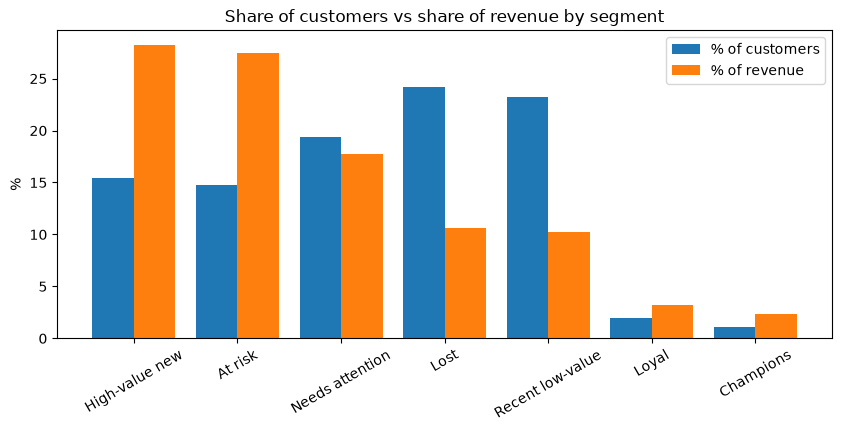

In [10]:
x = range(len(profile))
width = 0.4

plt.bar([i - width / 2 for i in x], profile["customer_share_%"], width=width, label="% of customers")
plt.bar([i + width / 2 for i in x], profile["revenue_share_%"], width=width, label="% of revenue")
plt.xticks(list(x), profile["segment"], rotation=30)
plt.title("Share of customers vs share of revenue by segment")
plt.ylabel("%")
plt.legend()
plt.show()

**Question 7: How do the segments compare on spend and recency?**

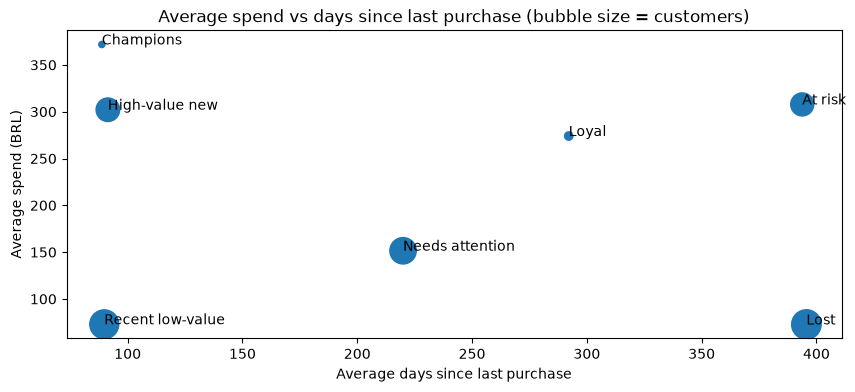

In [11]:
fig, ax = plt.subplots()
ax.scatter(profile["avg_recency_days"], profile["avg_spend"], s=profile["customers"] / 50)

for _, row in profile.iterrows():
    ax.annotate(row["segment"], (row["avg_recency_days"], row["avg_spend"]))

ax.set_title("Average spend vs days since last purchase (bubble size = customers)")
ax.set_xlabel("Average days since last purchase")
ax.set_ylabel("Average spend (BRL)")
plt.show()

## 6. Save

In [12]:
# saved for Power BI on Day 7
rfm.to_csv(PROCESSED_PATH + "rfm_customers.csv", index=False)
print("saved rfm_customers.csv -", len(rfm), "customers")

saved rfm_customers.csv - 93350 customers


## Observations

**Method**
- Reference date: 2018-08-30 (the day after the last purchase in the data).
- Recency and Monetary were scored 1-5 by quintile (18,670 customers in each score).
  - R = 5 means the last purchase was within 92 days; R = 1 means 382-714 days ago.
  - M = 5 means total spend of 208.54 BRL or more; M = 1 means 9.59-55.24 BRL.
- Frequency was split into one-time vs repeat because 90,549 of 93,350 customers (97.0%) ordered only once, so a 1-5 score would not separate them.

**Segments**
- Largest segment by customers: Lost, with 22,571 customers (24.18%) but only 10.64% of revenue.
- Largest segment by revenue: High-value new, with 28.23% of revenue from 15.44% of customers.
- Champions + Loyal (repeat buyers): 2,801 customers (3.00%) bringing in 5.60% of revenue. They spend more per customer (371.77 and 274.01 BRL on average) than the average customer (165.17 BRL).
- High-value new: 14,411 customers, 28.23% of revenue, average spend 302.08 BRL, last purchase about 91 days ago on average.
- At risk: 13,773 customers, 27.49% of revenue, average spend 307.77 BRL, but their last purchase was about 394 days ago on average.
- High-value new and At risk together are 30.19% of customers but 55.72% of revenue.
- Loyal customers have bought more than once but their last purchase was about 292 days ago on average, so many of them are drifting away.

**What it means for the business**
- Revenue depends almost entirely on one-time buyers. Turning even a small share of them into repeat customers is the biggest growth opportunity.
- High-value new customers are the best target for a second-purchase campaign: they spent a lot and bought recently.
- At risk customers spent as much as High-value new customers but have not returned in over a year. A win-back campaign could be tested on them, measuring how many place a second order.
- Repeat customers spend more per customer, which supports investing in retention rather than only acquiring new customers.
- Day 4 showed late deliveries get much worse reviews. Whether poor delivery also stops customers coming back is worth testing, but this analysis does not prove it.